<a href="https://colab.research.google.com/github/Ayesh2002/ml-student-dropout/blob/RF/02_random_forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 01. Set up the notebook

In [24]:
%pip -q install "scikit-learn==1.7.2"

import hashlib
import io
import json
import os
import urllib.request
import uuid
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
    classification_report, f1_score, make_scorer, recall_score,
)
from sklearn.model_selection import (
    GridSearchCV, ParameterSampler, StratifiedKFold,
    cross_validate, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

SEED = 42
SEARCH_JOBS = min(2, os.cpu_count() or 1)
RUN_ID = uuid.uuid4().hex[:8]
RESULTS = Path("rf_results") / RUN_ID
RESULTS.mkdir(parents=True, exist_ok=True)
print("scikit-learn:", sklearn.__version__)


scikit-learn: 1.6.1


##2. Load and inspect the dataset

In [25]:
DATA_URL = (
    "https://raw.githubusercontent.com/Ayesh2002/ml-student-dropout/"
    "5d932c6ff712451a084f57a6dd2df39fb6277890/data/student_dropout_academic_.csv"
)
with urllib.request.urlopen(DATA_URL, timeout=60) as response:
    data_bytes = response.read()
df = pd.read_csv(io.BytesIO(data_bytes))
df.columns = df.columns.str.strip()

assert df.shape == (4424, 37)
assert set(df["Target"]) == {"Dropout", "Enrolled", "Graduate"}
print("Dataset shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate records:", int(df.duplicated().sum()))
print(df["Target"].value_counts())
display(df.head())


Dataset shape: (4424, 37)
Missing values: 0
Duplicate records: 0
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nationality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


##3. Select the 24 first-semester features

In [26]:
X = df.drop(columns="Target").copy()
y = df["Target"].copy()
features = X.columns.tolist()

assert X.shape == (4424, 36)
assert len(features) == len(set(features)) == 36
assert "Target" not in features

print("Input shape:", X.shape)
print("Original predictors:", len(features))
print("Both semesters are included, matching the LR reference.")


Input shape: (4424, 36)
Original predictors: 36
Both semesters are included, matching the LR reference.


##4. Split the students and inspect training outcomes

Training students: 3539
Reserved benchmark students: 885


,Training students
Target,
Graduate,1767
Dropout,1137
Enrolled,635


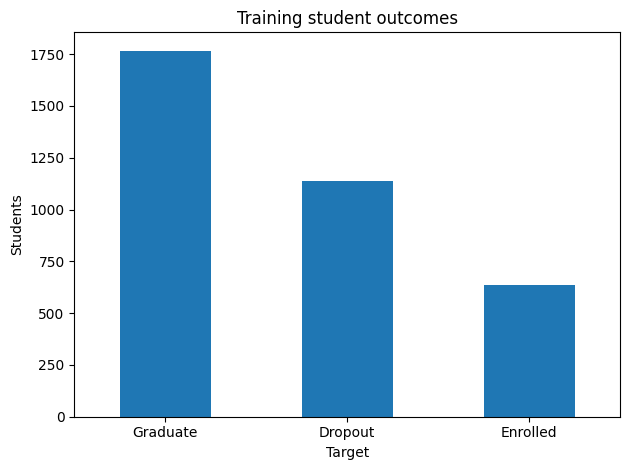

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED,
)

assert X_train.index.intersection(X_test.index).empty
assert len(X_train) == 3539
assert len(X_test) == 885

print("Training students:", len(X_train))
print("Reserved benchmark students:", len(X_test))

display(
    y_train.value_counts()
    .rename("Training students")
    .to_frame()
)

y_train.value_counts().plot.bar(
    title="Training student outcomes",
    rot=0,
)
plt.ylabel("Students")
plt.tight_layout()
plt.show()

Inspect training feature types and numeric summaries

In [30]:
eda_nominal = [
    "Marital status", "Application mode", "Application order", "Course",
    "Previous qualification", "Nationality", "Mother's qualification",
    "Father's qualification", "Mother's occupation", "Father's occupation",
]
eda_binary = [
    "Daytime/evening attendance", "Displaced", "Educational special needs",
    "Debtor", "Tuition fees up to date", "Gender", "Scholarship holder", "International",
]
eda_numeric = [c for c in X_train.columns if c not in eda_nominal + eda_binary]
eda_class_order = ["Dropout", "Enrolled", "Graduate"]
eda_train = X_train.copy().assign(Outcome=y_train)

eda_schema = pd.DataFrame({
    "Data type": X_train.dtypes.astype(str),
    "Missing": X_train.isna().sum(),
    "Distinct values": X_train.nunique(),
    "Role": [
        "Category" if c in eda_nominal else "Binary" if c in eda_binary else "Numeric"
        for c in X_train.columns
    ],
})
display(eda_schema)
display(X_train[eda_numeric].describe().transpose().round(2))
eda_rare = pd.DataFrame([
    {
        "Feature": c,
        "Distinct categories": X_train[c].nunique(),
        "Categories with fewer than 30 students": int((X_train[c].value_counts() < 30).sum()),
        "Students in those categories": int(X_train[c].value_counts().loc[lambda counts: counts < 30].sum()),
    }
    for c in eda_nominal
])
display(eda_rare)
for eda_semester in ["1st", "2nd"]:
    print("\n" + eda_semester + " semester: zero grades versus zero evaluations")
    display(pd.crosstab(
        X_train[f"Curricular units {eda_semester} sem (grade)"].eq(0).rename("Zero grade"),
        X_train[f"Curricular units {eda_semester} sem (evaluations)"].eq(0).rename("Zero evaluations"),
    ))
eda_schema.to_csv(RESULTS / "eda_feature_schema.csv")
eda_rare.to_csv(RESULTS / "eda_rare_categories.csv", index=False)


,Data type,Missing,Distinct values,Role
Marital status,int64,0,6,Category
Application mode,int64,0,18,Category
Application order,int64,0,8,Category
Course,int64,0,17,Category
Daytime/evening attendance,int64,0,2,Binary
Previous qualification,int64,0,17,Category
Previous qualification (grade),float64,0,99,Numeric
Nationality,int64,0,19,Category
Mother's qualification,int64,0,28,Category
Father's qualification,int64,0,32,Category


,count,mean,std,min,25%,50%,75%,max
Previous qualification (grade),3539.0,132.68,13.20,95.00,125.00,133.10,140.00,190.00
Admission grade,3539.0,126.88,14.53,95.00,117.80,126.00,134.90,190.00
Age at enrollment,3539.0,23.25,7.61,17.00,19.00,20.00,25.00,70.00
Curricular units 1st sem (credited),3539.0,0.72,2.38,0.00,0.00,0.00,0.00,20.00
Curricular units 1st sem (enrolled),3539.0,6.27,2.49,0.00,5.00,6.00,7.00,26.00
Curricular units 1st sem (evaluations),3539.0,8.29,4.19,0.00,6.00,8.00,10.00,45.00
Curricular units 1st sem (approved),3539.0,4.70,3.10,0.00,3.00,5.00,6.00,26.00
Curricular units 1st sem (grade),3539.0,10.62,4.87,0.00,11.00,12.32,13.40,18.88
Curricular units 1st sem (without evaluations),3539.0,0.14,0.66,0.00,0.00,0.00,0.00,12.00
Curricular units 2nd sem (credited),3539.0,0.55,1.92,0.00,0.00,0.00,0.00,19.00


,Feature,Distinct categories,Categories with fewer than 30 students,Students in those categories
0,Marital status,6,3,26
1,Application mode,18,7,55
2,Application order,8,2,2
3,Course,17,1,10
4,Previous qualification,17,10,68
5,Nationality,19,18,86
6,Mother's qualification,28,19,71
7,Father's qualification,32,23,84
8,Mother's occupation,31,21,117
9,Father's occupation,41,29,87



1st semester: zero grades versus zero evaluations


Zero evaluations,False,True
Zero grade,,
False,2957,0
True,297,285



2nd semester: zero grades versus zero evaluations


Zero evaluations,False,True
Zero grade,,
False,2834,0
True,376,329


Explore numeric distributions and outcome relationships

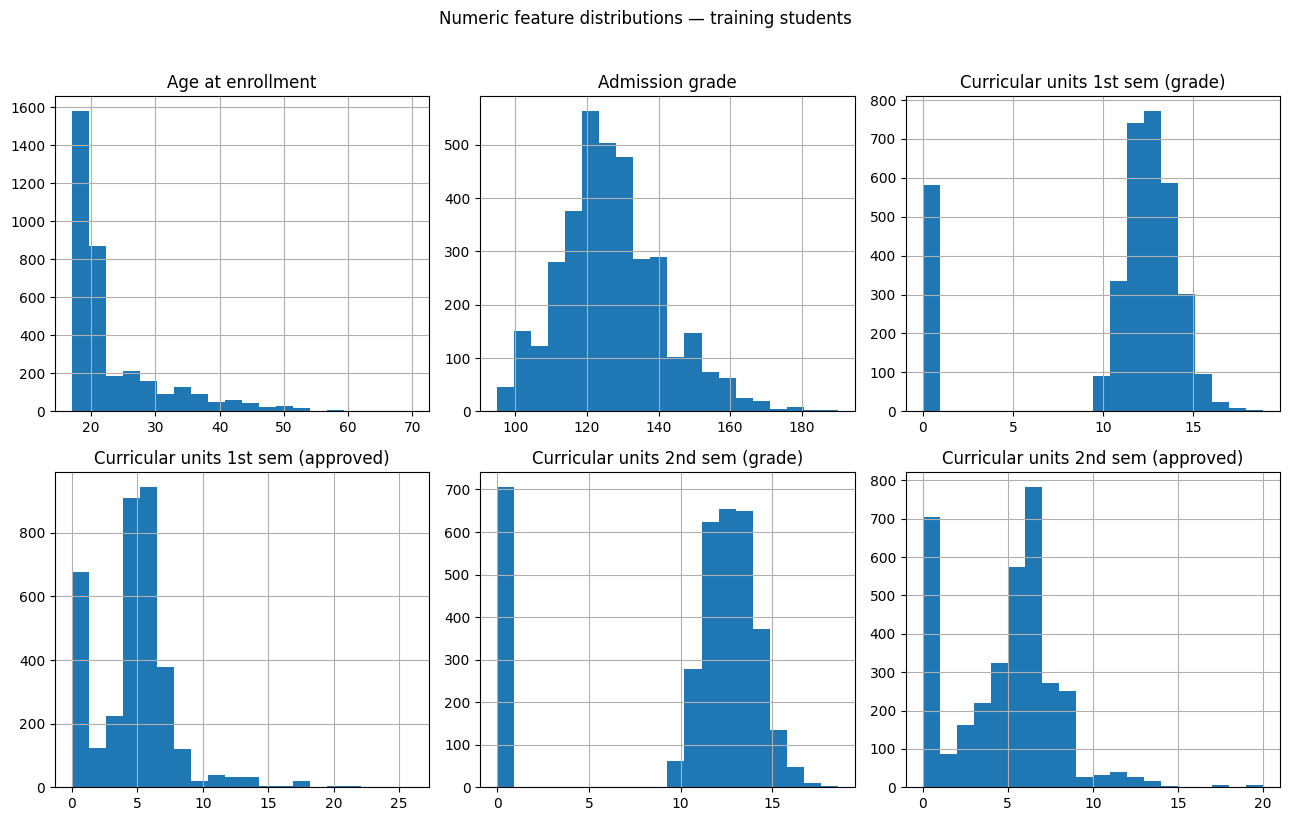

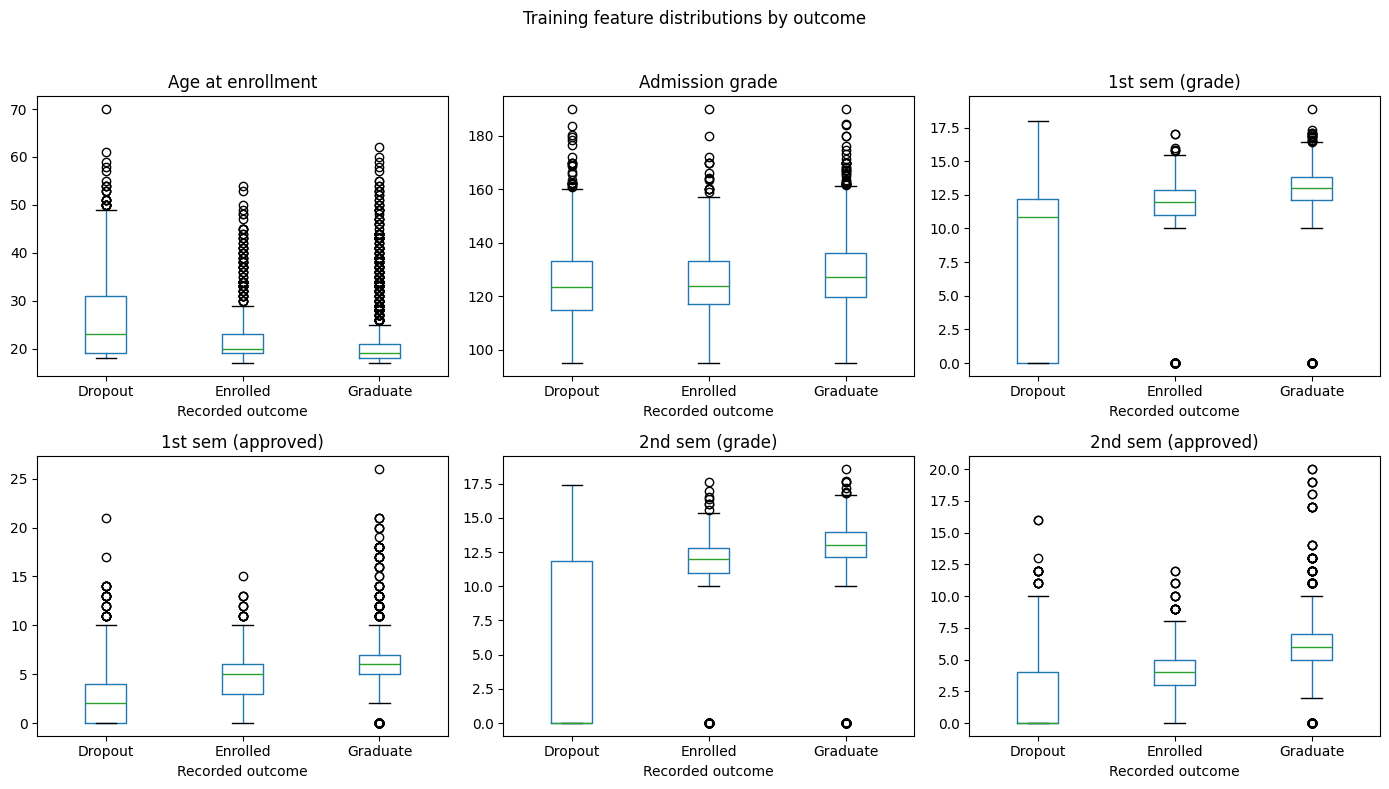

Age at enrollment        Admission grade          \
                    median   mean          median    mean   
Outcome                                                     
Dropout               23.0  26.07           123.3  124.81   
Enrolled              20.0  22.40           123.9  125.49   
Graduate              19.0  21.74           127.3  128.70   

         Curricular units 1st sem (grade)         \
                                   median   mean   
Outcome                                            
Dropout                             10.83   7.21   
Enrolled                            12.00  11.14   
Graduate                            13.00  12.63   

         Curricular units 1st sem (approved)        \
                                      median  mean   
Outcome                                              
Dropout                                  2.0  2.57   
Enrolled                                 5.0  4.36   
Graduate                                 6.0  6.20   

         Curricular units 2nd sem (grade)         \
                                   median   mean   
Outcome                                            
Dropout                               0.0   5.84   
Enrolled                             12.0  11.15   
Graduate                             13.0  12.67   

         Curricular units 2nd sem (approved)        
                                      median  mean  
Outcome                                             
Dropout                                  0.0  1.94  
Enrolled                                 4.0  4.10  
Graduate                                 6.0  6.16

In [31]:
eda_plot_columns = [
    "Age at enrollment", "Admission grade",
    "Curricular units 1st sem (grade)", "Curricular units 1st sem (approved)",
    "Curricular units 2nd sem (grade)", "Curricular units 2nd sem (approved)",
]
X_train[eda_plot_columns].hist(bins=20, figsize=(13, 8), layout=(2, 3))
plt.suptitle("Numeric feature distributions — training students", y=1.02)
plt.tight_layout()
plt.savefig(RESULTS / "eda_numeric_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

eda_figure, eda_axes = plt.subplots(2, 3, figsize=(14, 8))
for eda_ax, eda_column in zip(eda_axes.flat, eda_plot_columns):
    eda_train.boxplot(column=eda_column, by="Outcome", ax=eda_ax, grid=False)
    eda_ax.set_title(eda_column.replace("Curricular units ", ""))
    eda_ax.set_xlabel("Recorded outcome")
    eda_ax.set_ylabel("")
eda_figure.suptitle("Training feature distributions by outcome")
eda_figure.tight_layout(rect=[0, 0, 1, 0.96])
eda_figure.savefig(RESULTS / "eda_numeric_by_outcome.png", dpi=150, bbox_inches="tight")
plt.show()
display(eda_train.groupby("Outcome")[eda_plot_columns].agg(["median", "mean"]).round(2))


##5. Build preprocessing and the RF baseline

In [18]:
categorical = [
    "Marital status",
    "Application mode",
    "Application order",
    "Course",
    "Previous qualification",
    "Nationality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
]

numeric = [
    column for column in features
    if column not in categorical
]

preprocessor = ColumnTransformer([
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            (
                "encoder",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                ),
            ),
        ]),
        categorical,
    ),
    (
        "num",
        SimpleImputer(strategy="median"),
        numeric,
    ),
])

baseline = Pipeline([
    ("prep", preprocessor),
    (
        "rf",
        RandomForestClassifier(
            n_estimators=200,
            random_state=SEED,
            n_jobs=1,
        ),
    ),
])

scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
    "balanced_accuracy": "balanced_accuracy",
    "dropout_recall": make_scorer(
        recall_score,
        labels=["Dropout"],
        average="macro",
        zero_division=0,
    ),
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED,
)

print("Pipeline ready. No model has been fitted yet.")

Pipeline ready. No model has been fitted yet.


##6. Measure baseline performance using training cross-validation

In [19]:
baseline_cv = cross_validate(
    baseline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=SEARCH_JOBS,
    error_score="raise",
)

baseline_summary = pd.Series(
    {
        "Training accuracy": baseline_cv["train_accuracy"].mean(),
        **{
            f"CV {metric}": baseline_cv[f"test_{metric}"].mean()
            for metric in scoring
        },
    },
    name="Original RF",
)

display(baseline_summary.round(4).to_frame())
baseline_summary.to_csv(RESULTS / "baseline_cv.csv")

,Original RF
Training accuracy,1.0000
CV accuracy,0.7720
CV macro_f1,0.6761
CV balanced_accuracy,0.6677
CV dropout_recall,0.7695


##7. Tune Random Forest

In [20]:
base_params = {
    "rf__max_depth": None,
    "rf__min_samples_leaf": 1,
    "rf__max_features": "sqrt",
    "rf__class_weight": None,
    "prep__cat__encoder__min_frequency": None,
}

space = {
    "rf__max_depth": [None, 10, 20, 30],
    "rf__min_samples_leaf": [1, 2, 4, 8],
    "rf__max_features": ["sqrt", 0.3, 0.5, 0.8, 1.0],
    "rf__class_weight": [None, "balanced", "balanced_subsample"],
    "prep__cat__encoder__min_frequency": [None, 10, 30],
}

candidates = [
    base_params,
    {
        **base_params,
        "rf__max_features": 0.5,
    },
    {
        **base_params,
        "rf__max_features": 0.5,
        "rf__min_samples_leaf": 4,
        "rf__class_weight": "balanced_subsample",
    },
] + list(
    ParameterSampler(
        space,
        n_iter=9,
        random_state=SEED,
    )
)

grid = [
    {key: [value] for key, value in params.items()}
    for params in candidates
]

search = GridSearchCV(
    baseline,
    param_grid=grid,
    scoring=scoring,
    refit="accuracy",
    cv=cv,
    n_jobs=SEARCH_JOBS,
    pre_dispatch=SEARCH_JOBS,
    return_train_score=True,
    error_score="raise",
    verbose=1,
)

search.fit(X_train, y_train)

print("Selected settings:", search.best_params_)
print("Selected tuning-CV accuracy:", round(search.best_score_, 4))

cv_results = pd.DataFrame(search.cv_results_)

columns = [
    "rank_test_accuracy",
    "mean_train_accuracy",
    "mean_test_accuracy",
    "mean_test_macro_f1",
    "mean_test_dropout_recall",
    "params",
]

display(
    cv_results[columns]
    .sort_values("rank_test_accuracy")
    .head()
)

cv_results[columns].to_csv(
    RESULTS / "tuning_cv.csv",
    index=False,
)

assert (
    search.best_score_
    >= baseline_cv["test_accuracy"].mean() - 1e-12
)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Selected settings: {'prep__cat__encoder__min_frequency': None, 'rf__class_weight': 'balanced', 'rf__max_depth': 30, 'rf__max_features': 0.3, 'rf__min_samples_leaf': 2}
Selected tuning-CV accuracy: 0.7731


,rank_test_accuracy,mean_train_accuracy,mean_test_accuracy,mean_test_macro_f1,mean_test_dropout_recall,params
10,1,0.986578,0.773100,0.710555,0.747554,"{'prep__cat__encoder__min_frequency': None, 'r..."
11,2,0.995055,0.772250,0.699075,0.754602,"{'prep__cat__encoder__min_frequency': 10, 'rf_..."
0,3,1.000000,0.771972,0.676083,0.769534,"{'prep__cat__encoder__min_frequency': None, 'r..."
8,4,0.972097,0.771403,0.693473,0.751959,"{'prep__cat__encoder__min_frequency': None, 'r..."
1,5,1.000000,0.770840,0.693605,0.758973,"{'prep__cat__encoder__min_frequency': None, 'r..."


##8. Freeze the selected model and inspect overfitting

In [21]:
baseline_model = clone(baseline).set_params(
    rf__oob_score=True,
    rf__n_jobs=-1,
).fit(X_train, y_train)

selected_model = clone(search.best_estimator_).set_params(
    rf__oob_score=True,
    rf__n_jobs=-1,
).fit(X_train, y_train)

diagnostics = pd.DataFrame([
    {
        "Model": name,
        "Training accuracy": model.score(X_train, y_train),
        "OOB accuracy": model.named_steps["rf"].oob_score_,
    }
    for name, model in [
        ("Original RF", baseline_model),
        ("Selected RF", selected_model),
    ]
]).set_index("Model")

display(diagnostics.round(4))
diagnostics.to_csv(RESULTS / "training_diagnostics.csv")

frozen = {
    "run_id": RUN_ID,
    "prediction_time": "after first semester",
    "features": features,
    "target_classes": ["Dropout", "Enrolled", "Graduate"],
    "dataset_url": DATA_URL,
    "dataset_sha256": hashlib.sha256(data_bytes).hexdigest(),
    "seed": SEED,
    "test_size": 0.20,
    "selection_metric": "accuracy",
    "cv_folds": 5,
    "selected_parameters": search.best_params_,
    "tuning_cv_accuracy": float(search.best_score_),
    "sklearn_version": sklearn.__version__,
    "holdout_status": "Previously explored benchmark",
    "benchmark_evaluated": False,
}

print("Selected model frozen.")
print("Benchmark evaluation remains disabled below.")

,Training accuracy,OOB accuracy
Model,,
Original RF,1.0000,0.7683
Selected RF,0.9864,0.7768


Selected model frozen.
Benchmark evaluation remains disabled below.


##9. Evaluate the frozen models

In [22]:
RUN_BENCHMARK = False

if not RUN_BENCHMARK:
    print(
        "Benchmark evaluation is OFF. "
        "Finish training-only model selection first."
    )

else:
    rows = []
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    for ax, (name, model) in zip(
        axes,
        [
            ("Original RF", baseline_model),
            ("Selected RF", selected_model),
        ],
    ):
        pred = model.predict(X_test)

        rows.append({
            "Model": name,
            "Accuracy": accuracy_score(y_test, pred),
            "Macro-F1": f1_score(y_test, pred, average="macro"),
            "Balanced accuracy": balanced_accuracy_score(y_test, pred),
        })

        print("\n" + name)
        print(
            classification_report(
                y_test,
                pred,
                digits=3,
                zero_division=0,
            )
        )

        ConfusionMatrixDisplay.from_predictions(
            y_test,
            pred,
            labels=["Dropout", "Enrolled", "Graduate"],
            ax=ax,
            cmap="Blues",
            colorbar=False,
        )
        ax.set_title(name)

    plt.tight_layout()
    plt.show()

    test_results = pd.DataFrame(rows).set_index("Model")
    display(test_results.round(4))

    test_results.to_csv(RESULTS / "benchmark_results.csv")

    frozen["benchmark_evaluated"] = True
    frozen["selected_benchmark_accuracy"] = float(
        test_results.loc["Selected RF", "Accuracy"]
    )

Benchmark evaluation is OFF. Finish training-only model selection first.


##10. Save the model and results

In [23]:
joblib.dump(
    selected_model,
    RESULTS / "random_forest.joblib",
)

(RESULTS / "experiment.json").write_text(
    json.dumps(frozen, indent=2),
    encoding="utf-8",
)

split_record = pd.concat([
    pd.DataFrame({
        "Dataset row": X_train.index,
        "Partition": "training",
    }),
    pd.DataFrame({
        "Dataset row": X_test.index,
        "Partition": "benchmark",
    }),
]).sort_values("Dataset row")

split_record.to_csv(
    RESULTS / "student_split.csv",
    index=False,
)

print("Saved model and results to:", RESULTS)

Saved model and results to: rf_results/a973d941
